TR02 → 165.08 km
TR03 → 160.20 km
TR04 → 156.59 km
TR05 → 153.11 km
TR08 → 140.56 km
TR10 → 136.01 km
TR11 → 131.48 km
TR12 → 128.89 km
TR13 → 125.49 km
TR14 → 120.62 km
TR15 → 116.83 km
TR16 → 108.97 km
TR17 → 106.58 km
TR18 → 103.63 km
TR19 → 99.80 km
TR20 → 95.94 km
TR21 → 92.48 km
TR22 → 87.26 km
TR23 → 84.51 km
TR24 → 81.78 km
TR25 → 77.85 km
TR26 → 75.88 km
TR27 → 70.88 km
TR27A → 66.62 km
TR28 → 68.77 km
TR29 → 65.98 km
TR29A → 65.84 km
TR30 → 62.19 km
TR31 → 59.36 km
TR32N → 55.15 km
TR34 → 48.14 km
TR35 → 45.08 km
TR36 → 39.83 km
TR37 → 35.30 km
TR38 → 31.20 km
TR40 → 22.27 km
TR41 → 22.59 km
TR42 → 19.55 km
TR43 → 17.11 km


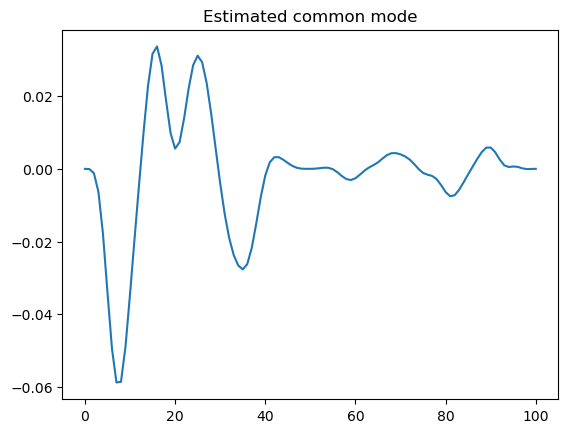

Common-mode removal applied to stacked sections

===== SECTION SUMMARY =====
Stations stacked: 39
Samples per trace: 101
Sampling interval: 0.2 s



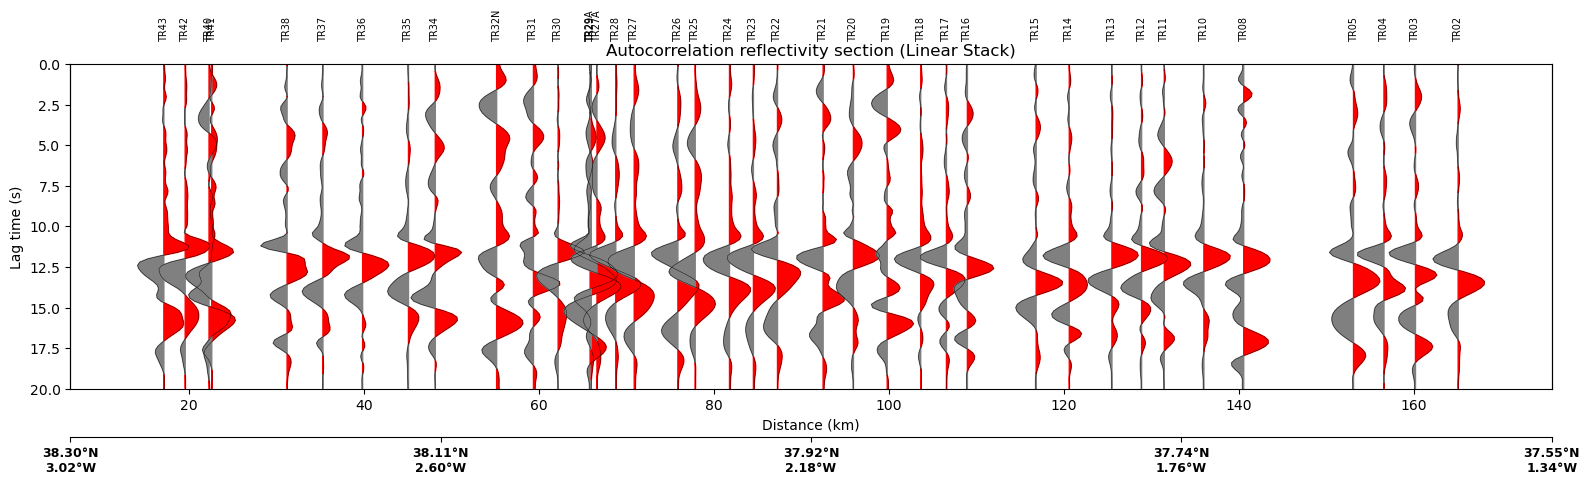

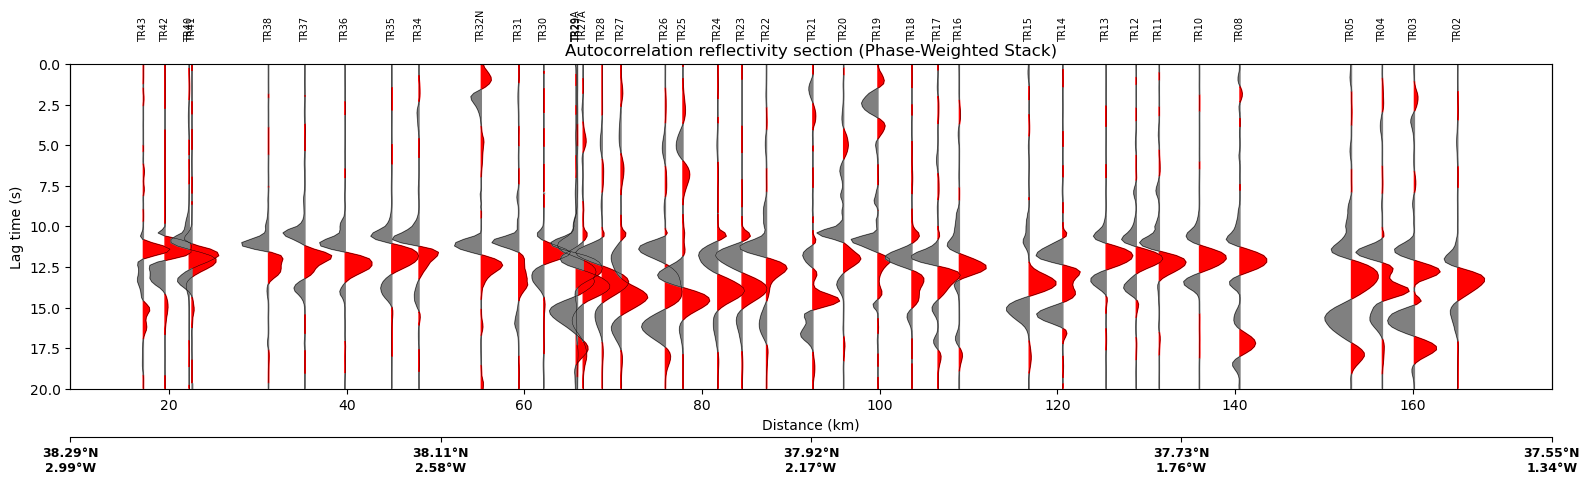

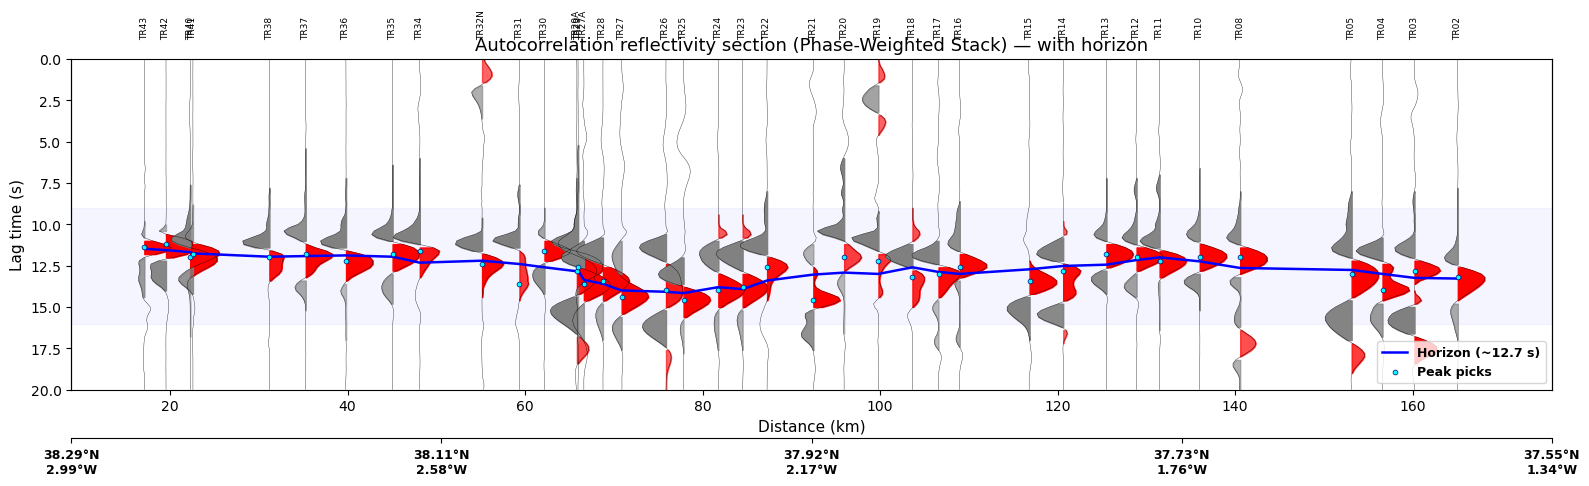

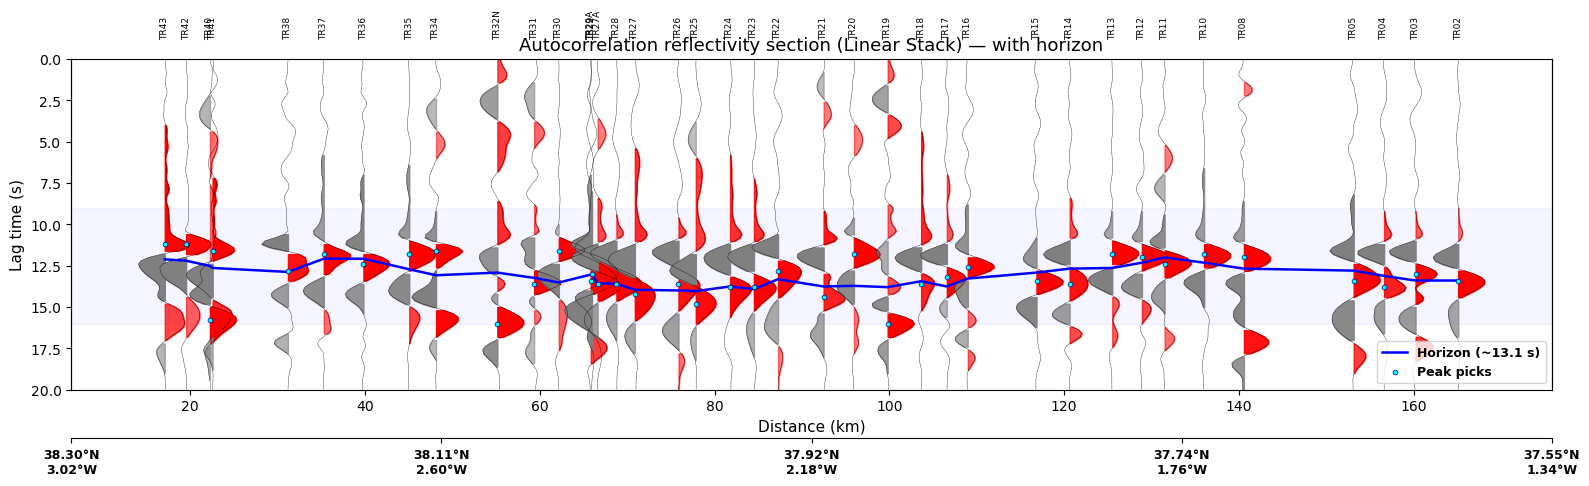

Horizon picks (PWS): [11.48 11.56 11.68 11.76 11.96 11.92 11.88 11.96 12.32 12.2  12.4  12.6
 12.84 12.8  13.36 13.6  14.   14.08 14.16 13.8  13.92 13.4  13.04 12.92
 13.   12.6  12.88 13.   12.72 12.52 12.44 12.16 12.   12.24 12.64 12.76
 13.   13.24 13.28]
Median horizon lag  : 12.72 s


In [ ]:
### POST PROCESSING with moho plot
import numpy as np
import scipy.signal as signal
from scipy.signal import savgol_filter, hilbert
import matplotlib.pyplot as plt
import glob
import os
from obspy.geodetics import gps2dist_azimuth
from obspy import read_inventory

acf_root = r"D:\Alan CUSAT- dissertation\TRANSCORBE\ACF_CCF_123_HHZ"
stationxml = r"D:\Alan CUSAT- dissertation\TRANSCORBE\TRANSCORBE.xml"
TARGET_DT = 0.2
MAXLAG = 20
period_min = 1
period_max = 6

profile_start = (38.33, -3.08)
profile_end   = (37.43, -1.08)
_, profile_azimuth, _ = gps2dist_azimuth(
    profile_start[0],
    profile_start[1],
    profile_end[0],
    profile_end[1])
def projected_profile_distance(station):
    lat, lon = station_coords[station]
    dist, az, _ = gps2dist_azimuth(
        profile_start[0],
        profile_start[1],
        lat,
        lon)
    projected = dist * np.cos(np.deg2rad(az - profile_azimuth))
    return projected / 1000.0

def cosine_taper(n, pct=0.1):
    m = int(pct * n)
    w = np.ones(n)
    taper = np.sin(np.linspace(0, np.pi/2, m))**2
    w[:m] = taper
    w[-m:] = taper[::-1]
    return w

def zero_lag_cosine_taper(acf, dt, mute_sec=4):
    n = len(acf)
    center = n // 2
    mute_samples = int(mute_sec / dt)
    window = np.ones(n)
    taper = np.sin(
        np.linspace(0, np.pi/2, mute_samples))**2
    window[center-mute_samples:center] = taper[::-1]
    window[center:center+mute_samples] = taper
    return acf * window

def bandpass_acf(acf, dt, period_min=1.0, period_max=6.0, order=4):
    if period_min <= 0 or period_max <= 0:
        raise ValueError("Periods must be positive.")
    if period_min >= period_max:
        raise ValueError("period_min must be smaller than period_max.")
    fs = 1.0 / dt
    nyq = fs / 2.0
    fmin = 1.0 / period_max
    fmax = 1.0 / period_min
    if fmax >= nyq:
        raise ValueError("Upper frequency exceeds Nyquist.")
    if len(acf) < 3 * order:
        raise ValueError("ACF too short for filtering.")
    sos = signal.butter(order,
                        [fmin, fmax],
                        btype='band',
                        fs=fs,
                        output='sos')
    return signal.sosfiltfilt(sos, acf)

def remove_trend(acf):
    window = int(2 / TARGET_DT)
    if window % 2 == 0:
        window += 1
    trend = savgol_filter(acf, window, 2)
    return acf - trend

"""def mute_zero_lag(acf):
    n = len(acf)
    lags = (np.arange(n) - n//2) * TARGET_DT
    acf[(lags >= 0) & (lags < 3)] = 0
    return acf"""

def phase_shift(acf,TARGET_DT):
    n = len(acf)
    freqs = np.fft.fftfreq(n, d=TARGET_DT)
    fft_data = np.fft.fft(acf)
    phase_shift = np.zeros_like(fft_data, dtype=complex)
    for i, f in enumerate(freqs):
        if f > 0:
            phase_shift[i] = np.exp(1j * np.pi / 2)
        elif f < 0:
            phase_shift[i] = np.exp(-1j * np.pi / 2)
        else:
            phase_shift[i] = 1.0
    return np.real(np.fft.ifft(fft_data * phase_shift))

def phase_weighted_stack(data):
    analytic = hilbert(data, axis=1)
    phase = analytic / np.abs(analytic + 1e-10)
    coherence = np.abs(np.mean(phase, axis=0))**2
    linear = np.mean(data, axis=0)
    return linear * coherence

inventory = read_inventory(stationxml)
station_coords = {}
for net in inventory:
    for sta in net:
        station_coords[sta.code] = (sta.latitude, sta.longitude)
reference_station = list(station_coords.keys())[0]

def distance_from_reference(sta):
    lat1, lon1 = station_coords[reference_station]
    lat2, lon2 = station_coords[sta]
    dist = gps2dist_azimuth(lat1, lon1, lat2, lon2)[0]
    return dist / 1000

station_dirs = sorted(glob.glob(os.path.join(acf_root, "*")))
section_linear = []
section_pws = []
distances = []
station_names = []
station_day_counts = []
for station_dir in station_dirs:
    station = os.path.basename(station_dir)
    if station not in station_coords:
        print(f"Skipping {station}")
        continue
    acf_files = sorted(glob.glob(os.path.join(station_dir, "*.npy")))
    if len(acf_files) == 0:
        continue
    traces = []
    for file in acf_files:
        acf = np.load(file)
        acf = bandpass_acf(acf, TARGET_DT, period_min, period_max)
        #acf = remove_trend(acf)
        acf *= cosine_taper(len(acf))
        acf = zero_lag_cosine_taper(acf, TARGET_DT, mute_sec=3)
        #acf = mute_zero_lag(acf)
        traces.append(acf)
    traces = np.vstack(traces)
    linear_stack = np.mean(traces, axis=0)
    num_days = traces.shape[0]
    section_linear.append(linear_stack)
    section_pws.append(traces)
    station_day_counts.append(num_days)
    d = projected_profile_distance(station)
    distances.append(d)
    station_names.append(station)
    print(f"{station} → {d:.2f} km")
section_linear = np.array(section_linear)
distances = np.array(distances)
order = np.argsort(distances)
section_linear = section_linear[order]
section_pws = [section_pws[i] for i in order]
distances = distances[order]
station_names = np.array(station_names)[order]
station_day_counts = np.array(station_day_counts)
station_day_counts = station_day_counts[order]

common_mode_linear = np.average(
    section_linear,
    axis=0,
    weights=station_day_counts)
plt.plot(common_mode_linear)
plt.title("Estimated common mode")
plt.show()
section_linear = section_linear - common_mode_linear[np.newaxis, :]
section_linear = np.array([
    phase_shift(tr, TARGET_DT)
    for tr in section_linear])
section_pws = np.array([
    phase_weighted_stack(
        np.array([phase_shift(tr, TARGET_DT) for tr in traces]))
    for traces in section_pws])
#common_mode_pws = np.mean(section_pws, axis=0)
#section_pws = section_pws - common_mode_pws
print("Common-mode removal applied to stacked sections")

time = np.arange(section_linear.shape[1]) * TARGET_DT
print("\n===== SECTION SUMMARY =====")
print(f"Stations stacked: {section_linear.shape[0]}")
print(f"Samples per trace: {section_linear.shape[1]}")
print(f"Sampling interval: {TARGET_DT} s")
print("===========================\n")

import matplotlib.font_manager as fm

def plot_section(section, distances, station_names, title,
                 scale=3, maxlag=MAXLAG, target_dt=TARGET_DT,
                 geo_n_ticks=5, geo_label_color="black"):

    # Shared font for legend and geographic labels (match this to other plots)
    legend_font = fm.FontProperties(size=9, weight='bold')

    # center zero-lag as before
    section = np.roll(section, -section.shape[1] // 2, axis=1)

    plt.figure(figsize=(16,5))
    n = section.shape[1]
    lags = np.arange(n) * target_dt
    mask = lags <= maxlag
    time_plot = lags[mask]

    for i in range(len(distances)):
        trace = section[i][mask].copy()
        # optional mute around early times if you used that earlier:
        # trace[lags[mask] < 3] = 0
        # normalize for plotting
        mx = np.max(np.abs(trace)) + 1e-10
        trace = trace / mx
        x = distances[i] + trace * scale
        plt.plot(x, time_plot, color='black', linewidth=0.3)
        plt.fill_betweenx(time_plot, distances[i], x,
                          where=(trace > 0), color='red', interpolate=True)
        plt.fill_betweenx(time_plot, distances[i], x,
                          where=(trace < 0), color='gray', interpolate=True)
        plt.text(distances[i], -1.5, station_names[i],
                 fontsize=7, rotation=90, ha='center')

    plt.ylim(0, maxlag)
    plt.gca().invert_yaxis()
    plt.xlabel("Distance (km)")
    plt.ylabel("Lag time (s)")
    plt.title(title)


    total_dist_m, _, _ = gps2dist_azimuth(profile_start[0], profile_start[1],
                                          profile_end[0], profile_end[1])
    total_dist_km = total_dist_m / 1000.0

    def get_coords_at_dist(dist_km):
        frac = dist_km / total_dist_km
        frac = np.clip(frac, 0.0, 1.0)
        lat = profile_start[0] + frac * (profile_end[0] - profile_start[0])
        lon = profile_start[1] + frac * (profile_end[1] - profile_start[1])
        return lat, lon

    def fmt_coord(lat, lon):
        lat_dir = 'N' if lat >= 0 else 'S'
        lon_dir = 'E' if lon >= 0 else 'W'
        return f"{abs(lat):.2f}°{lat_dir}\n{abs(lon):.2f}°{lon_dir}"

    ax = plt.gca()
    ax_geo = ax.twiny()
    ax_geo.xaxis.set_ticks_position('bottom')
    ax_geo.xaxis.set_label_position('bottom')
    ax_geo.spines['bottom'].set_position(('outward', 35))

    x_min, x_max = ax.get_xlim()
    tick_positions = np.linspace(x_min, x_max, geo_n_ticks)
    tick_labels = []
    for tp in tick_positions:
        latp, lonp = get_coords_at_dist(tp)
        tick_labels.append(fmt_coord(latp, lonp))

    ax_geo.set_xlim(x_min, x_max)
    ax_geo.set_xticks(tick_positions)
    ax_geo.set_xticklabels(tick_labels, fontproperties=legend_font, color=geo_label_color)
    ax_geo.spines['top'].set_visible(False)

    if 'HORIZON_WINDOW' in globals():
        t0, t1 = HORIZON_WINDOW
        ax.axhspan(t0, t1, color='black', alpha=0.04, zorder=1)

    plt.tight_layout()
    plt.show()

plot_section(
    section_linear,
    distances,
    station_names,
    "Autocorrelation reflectivity section (Linear Stack)")
plot_section(
    section_pws,
    distances,
    station_names,
    "Autocorrelation reflectivity section (Phase-Weighted Stack)")

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from scipy.ndimage import uniform_filter1d
from scipy.signal import hilbert

HORIZON_WINDOW = (9.0, 16.0)  
SCALE          = 3            
AMP_CLIP       = 0.3          
HORIZON_SMOOTH = 5            

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
from scipy.ndimage import uniform_filter1d
from scipy.signal import hilbert

try:
    from obspy.geodetics import gps2dist_azimuth
except Exception:
    try:
        from geographiclib.geodesic import Geodesic
        def gps2dist_azimuth(lat1, lon1, lat2, lon2):
            g = Geodesic.WGS84.Inverse(lat1, lon1, lat2, lon2)
            dist_m = g['s12']
            az = g['azi1']
            baz = g['azi2']
            return dist_m, az, baz
    except Exception:
        try:
            from pyproj import Geod
            _geod = Geod(ellps='WGS84')
            def gps2dist_azimuth(lat1, lon1, lat2, lon2):
                az, baz, dist_m = _geod.inv(lon1, lat1, lon2, lat2)
                return dist_m, az, baz
        except Exception:
            def _haversine(lat1, lon1, lat2, lon2):
                R = 6371000.0
                phi1 = np.deg2rad(lat1); phi2 = np.deg2rad(lat2)
                dphi = np.deg2rad(lat2 - lat1); dlambda = np.deg2rad(lon2 - lon1)
                a = np.sin(dphi/2.0)**2 + np.cos(phi1)*np.cos(phi2)*np.sin(dlambda/2.0)**2
                return 2*R*np.arcsin(np.sqrt(a))
            def _initial_bearing(lat1, lon1, lat2, lon2):
                phi1 = np.deg2rad(lat1); phi2 = np.deg2rad(lat2)
                lam1 = np.deg2rad(lon1); lam2 = np.deg2rad(lon2)
                y = np.sin(lam2 - lam1) * np.cos(phi2)
                x = np.cos(phi1)*np.sin(phi2) - np.sin(phi1)*np.cos(phi2)*np.cos(lam2 - lam1)
                brng = np.rad2deg(np.arctan2(y, x))
                return (brng + 360) % 360
            def gps2dist_azimuth(lat1, lon1, lat2, lon2):
                dist_m = _haversine(lat1, lon1, lat2, lon2)
                az = _initial_bearing(lat1, lon1, lat2, lon2)
                baz = (_initial_bearing(lat2, lon2, lat1, lon1) + 180) % 360
                return dist_m, az, baz

HORIZON_WINDOW = (9.0, 16.0)   
SCALE          = 3             
AMP_CLIP       = 0.3           
HORIZON_SMOOTH = 5             
GEO_N_TICKS    = 5             
GEO_LABEL_COLOR = "black"      

legend_font = fm.FontProperties(size=9, weight='bold')

def plot_section_with_horizon(section, distances, station_names, title,
                              horizon_window=HORIZON_WINDOW,
                              scale=SCALE,
                              amp_clip=AMP_CLIP,
                              horizon_smooth=HORIZON_SMOOTH,
                              geo_n_ticks=GEO_N_TICKS):

    section = np.roll(section, -section.shape[1] // 2, axis=1)
    n_samples = section.shape[1]
    lags      = np.arange(n_samples) * TARGET_DT      
    mask      = lags <= MAXLAG
    time_plot = lags[mask]
    t0, t1      = horizon_window
    pick_mask   = (time_plot >= t0) & (time_plot <= t1)
    horizon_lags = []

    for i in range(section.shape[0]):
        tr = section[i][mask].copy()
        tr_norm = tr / (np.max(np.abs(tr)) + 1e-10)
        window_trace = tr_norm[pick_mask]
        if window_trace.size == 0:
            horizon_lags.append(np.nan)
            continue
        idx_in_window = np.argmax(window_trace)
        horizon_lags.append(time_plot[pick_mask][idx_in_window])
    horizon_lags = np.array(horizon_lags)

    if horizon_smooth > 1:
        horizon_lags_smooth = uniform_filter1d(horizon_lags,
                                               size=horizon_smooth,
                                               mode='nearest')
    else:
        horizon_lags_smooth = horizon_lags.copy()
    fig, ax = plt.subplots(figsize=(16,5))

    for i in range(section.shape[0]):
        tr = section[i][mask].copy()
        envelope = np.abs(hilbert(tr))
        env_norm  = envelope / (np.max(envelope) + 1e-10)  # 0-1
        tr_norm = tr / (np.max(np.abs(tr)) + 1e-10)
        x = distances[i] + tr_norm * scale
        ax.plot(x, time_plot, color='black', linewidth=0.25, zorder=3)
        pos = tr_norm > 0
        neg = tr_norm < 0
        def fill_colored(ax, time_plot, x, distances, i, mask_bool, color,
                         env_norm, amp_clip):
            in_seg   = False
            seg_start = 0
            for k in range(len(mask_bool)):
                if mask_bool[k] and not in_seg:
                    seg_start = k
                    in_seg    = True
                elif (not mask_bool[k] or k == len(mask_bool) - 1) and in_seg:
                    seg_end = k if not mask_bool[k] else k + 1
                    in_seg  = False
                    sl      = slice(seg_start, seg_end)
                    peak_amp = np.max(env_norm[sl])
                    if peak_amp < amp_clip:
                        continue
                    alpha = np.clip(0.3 + 0.7 * peak_amp, 0, 1)
                    ax.fill_betweenx(
                        time_plot[sl],
                        distances[i],
                        x[sl],
                        color=color,
                        alpha=alpha,
                        interpolate=True,
                        zorder=2)
        fill_colored(ax, time_plot, x, distances, i,  pos, 'red',  env_norm, amp_clip)
        fill_colored(ax, time_plot, x, distances, i,  neg, 'gray', env_norm, amp_clip)
        ax.text(distances[i], -1.2, station_names[i],
                fontsize=6.5, rotation=90, ha='center', va='bottom')
    sort_idx = np.argsort(distances)
    ax.plot(distances[sort_idx], horizon_lags_smooth[sort_idx],
            color='blue', linewidth=1.8, linestyle='-',
            label=f'Horizon (~{np.nanmedian(horizon_lags_smooth):.1f} s)',
            zorder=5)
    ax.scatter(distances, horizon_lags, s=12, color='cyan',
               edgecolors='navy', linewidths=0.5, zorder=6,
               label='Peak picks')
    ax.set_ylim(0, MAXLAG)
    ax.invert_yaxis()
    ax.set_xlabel("Distance (km)", fontsize=11)
    ax.set_ylabel("Lag time (s)", fontsize=11)
    ax.set_title(title, fontsize=13)
    ax.legend(loc='lower right', prop=legend_font, framealpha=0.8)
    total_dist_m, _, _ = gps2dist_azimuth(profile_start[0], profile_start[1],
                                          profile_end[0], profile_end[1])
    total_dist_km = total_dist_m / 1000.0

    def get_coords_at_dist(dist_km):
        frac = dist_km / total_dist_km
        frac = np.clip(frac, 0.0, 1.0)
        lat = profile_start[0] + frac * (profile_end[0] - profile_start[0])
        lon = profile_start[1] + frac * (profile_end[1] - profile_start[1])
        return lat, lon

    def fmt_coord(lat, lon):
        lat_dir = 'N' if lat >= 0 else 'S'
        lon_dir = 'E' if lon >= 0 else 'W'
        return f"{abs(lat):.2f}°{lat_dir}\n{abs(lon):.2f}°{lon_dir}"

    ax_geo = ax.twiny()
    ax_geo.xaxis.set_ticks_position('bottom')
    ax_geo.xaxis.set_label_position('bottom')
    ax_geo.spines['bottom'].set_position(('outward', 35))

    x_min, x_max = ax.get_xlim()
    tick_positions = np.linspace(x_min, x_max, geo_n_ticks)
    tick_labels = []
    for tp in tick_positions:
        latp, lonp = get_coords_at_dist(tp)
        tick_labels.append(fmt_coord(latp, lonp))

    ax_geo.set_xlim(x_min, x_max)
    ax_geo.set_xticks(tick_positions)
    ax_geo.set_xticklabels(tick_labels, fontproperties=legend_font, color=GEO_LABEL_COLOR)
    ax_geo.spines['top'].set_visible(False)

    t0, t1 = horizon_window
    ax.axhspan(t0, t1, color='blue', alpha=0.04, zorder=1)
    plt.tight_layout()
    plt.show()
    return horizon_lags_smooth

horizon_pws = plot_section_with_horizon(
    section_pws, distances, station_names,
    "Autocorrelation reflectivity section (Phase-Weighted Stack) — with horizon",
    horizon_window=HORIZON_WINDOW,)

horizon_lin = plot_section_with_horizon(
    section_linear, distances, station_names,
    "Autocorrelation reflectivity section (Linear Stack) — with horizon",
    horizon_window=HORIZON_WINDOW,)
print("Horizon picks (PWS):", np.round(horizon_pws, 2))
print("Median horizon lag  :", np.round(np.median(horizon_pws), 2), "s")